# AlphaGenome: does a CALR-locus variant affect *KLF1*?

Zero-shot cis screen via the **hosted AlphaGenome API** (inference only — the model runs on
DeepMind's servers; nothing is downloaded or fine-tuned here).

In one 1 Mb window covering both genes:
1. **predict** REF vs ALT tracks for RNA-seq + contact maps (visual),
2. **score** the quantitative effect on *KLF1* expression and on local 3D contacts.

Verified against `alphagenome` SDK **0.6.1**. Coordinates are **hg38, 1-based**.

> **Run order:** top to bottom. Re-run the predict/score cells after changing the variant
> or ontology in the **Config** cell — that's the whole iteration loop.

## Setup

Pick your conda env as the kernel (top-right → *Select Kernel*), then run the install cell
once. `ipykernel` must be in that env for it to appear (`conda install ipykernel`).

In [1]:
# Run once per environment. Safe to re-run.
%pip install -q alphagenome matplotlib pandas anndata
# pyfaidx only needed if you use a local FASTA instead of the Ensembl REST default:
# %pip install -q pyfaidx

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from alphagenome.data import genome
from alphagenome.models import dna_client, variant_scorers
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

# inline, reasonably sharp figures
%matplotlib inline
plt.rcParams["figure.dpi"] = 120

## API key

Read from the `ALPHAGENOME_API_KEY` environment variable if set, otherwise prompt (the
key is **not** stored in the notebook). Free non-commercial key from DeepMind.

In [3]:
import os, getpass
API_KEY = os.environ.get("ALPHAGENOME_API_KEY") or getpass.getpass("AlphaGenome API key: ")
model = dna_client.create(API_KEY)
print("model client ready")

AlphaGenome API key:  ········


model client ready


## ⚠️ What this notebook can and cannot test — read first

The canonical CALR lesions are **exon-9 coding frameshifts** (type 1 = 52 bp deletion,
type 2 = 5 bp insertion). Their oncogenic mechanism is **trans / post-transcriptional**:
mutant protein → MPL binding → constitutive JAK/STAT5 signaling → downstream transcriptional
reprogramming. **AlphaGenome is a cis sequence-to-assay model** — it does not translate, fold
protein, or simulate signaling. So:

- A **near-zero predicted KLF1 effect for del52/ins5 is the expected result**, and is *not*
  evidence about the real (trans) mechanism — it only says a coding frameshift 56 kb away
  doesn't act as a distal KLF1 enhancer variant.
- What AlphaGenome *can* legitimately test here: the **cis** effect of each lesion on **CALR's
  own** RNA-seq / splicing / local chromatin & contacts, and the cis effect of any
  **non-coding** locus variant on KLF1.

Treat the KLF1 numbers below as a cis screen / null check, not as a model of CALR-mutant biology.

## Config — EDIT THIS CELL

All coordinates **hg38, 1-based**, from ClinVar (MANE `NM_004343.4`). CALR is **+ strand**, so
cDNA and genomic run the same direction; all lesions are in exon 9. *KLF1* is minus-strand
(TSS ~12.887 Mb); the CALR locus is ~12.94 Mb.

REF bases are fetched from the **reference** (Ensembl REST by default — no download — or a local
hg38 FASTA), never hand-typed. The reference build must be **GRCh38**.

In [17]:
CHROM     = "chr19"
KLF1_GENE = "KLF1"

# --- CALR exon-9 lesion coordinates (hg38, 1-based, from ClinVar) ---
# del52 (type 1): NC_000019.10:g.12943758_12943809del   (52 bp; VCV000097006)
DEL52_START, DEL52_END = 12_943_758, 12_943_809
# ins5 (type 2): c.1154_1155insTTGTC -> g.12943813_12943814insTTGTC
#   DERIVED from c.1142A>C = g.12943801 (+ strand, exon 9). VERIFY via VEP/Mutalyzer.
INS5_ANCHOR, INS5_SEQ = 12_943_813, "TTGTC"

# Path to a local hg38 FASTA (bgzipped ok). Example: GRCh38 primary assembly.
FASTA = "/path/to/GRCh38.primary_assembly.genome.fa"

# K562 (EFO:0002067): best-covered hematopoietic context AND has contact maps.
ONTOLOGY_TERMS = ["EFO:0002067"]

# 1 Mb window centered on the CALR exon-9 lesion site -> covers KLF1 + CALR.
SEQ_LEN     = dna_client.SUPPORTED_SEQUENCE_LENGTHS["SEQUENCE_LENGTH_1MB"]
CENTER      = DEL52_START
start       = CENTER - SEQ_LEN // 2
interval    = genome.Interval(chromosome=CHROM, start=start, end=start + SEQ_LEN)
print("Interval:", interval, f"({interval.end - interval.start} bp)")
print("contains KLF1 TSS (~12.887 Mb):", interval.start <= 12_887_201 <= interval.end)

Interval: chr19:12419470-13468046:. (1048576 bp)
contains KLF1 TSS (~12.887 Mb): True


### Build the three CALR states from the reference

`WT` is implicit — it's the **REF arm** of every `predict_variant` call, so there's no separate
object. We construct `del52` and `ins5` with VCF-style anchor encoding (anchor base precedes the
event), reading the needed reference bases either from **Ensembl REST** (no download — default) or
from a **local hg38 FASTA**. Both return GRCh38 bases; pick whichever you have.

In [5]:
REF_SOURCE = "ensembl"          # "ensembl" (no download) or "fasta" (local file)
FASTA      = "/path/to/GRCh38.primary_assembly.genome.fa"   # only used if REF_SOURCE=="fasta"

def fetch_ensembl(chrom, p1, p2):
    """GRCh38 bases for chrom:p1..p2 (1-based inclusive, + strand) via Ensembl REST."""
    import urllib.request, json
    c = chrom[3:] if chrom.startswith("chr") else chrom
    url = (f"https://rest.ensembl.org/sequence/region/human/{c}:{p1}..{p2}:1"
           "?content-type=application/json")
    req = urllib.request.Request(url, headers={"Content-Type": "application/json",
                                               "User-Agent": "alphagenome-helper"})
    with urllib.request.urlopen(req, timeout=30) as r:
        d = json.load(r)
    assert "GRCh38" in d["id"], f"unexpected assembly in {d['id']}"   # guard
    return d["seq"].upper()

def fetch_fasta(chrom, p1, p2):
    from pyfaidx import Fasta
    global _FA
    try: _FA
    except NameError: _FA = Fasta(FASTA, sequence_always_upper=True)
    return str(_FA[chrom][p1-1:p2])

fetch = fetch_ensembl if REF_SOURCE == "ensembl" else fetch_fasta

# del52: anchor at DEL52_START-1; REF = anchor + 52 deleted (53 bp); ALT = anchor
anchor   = DEL52_START - 1
ref_del  = fetch(CHROM, anchor, DEL52_END)
assert len(ref_del) == 53, f"expected 53 bp, got {len(ref_del)} — check coords/assembly"
del52 = genome.Variant(CHROM, anchor, ref_del, ref_del[0], "CALR_del52")

# ins5: anchor at INS5_ANCHOR; REF = 1 bp; ALT = anchor + TTGTC
ref_ins  = fetch(CHROM, INS5_ANCHOR, INS5_ANCHOR)
ins5 = genome.Variant(CHROM, INS5_ANCHOR, ref_ins, ref_ins + INS5_SEQ, "CALR_ins5")

for v in (del52, ins5):
    net = len(v.alternate_bases) - len(v.reference_bases)
    print(f"{v.name}: POS {v.position} | REF {len(v.reference_bases)} | "
          f"ALT {len(v.alternate_bases)} | net {net:+d} (frame {net % 3:+d})")
print("\nSanity: del52 net should be -52, ins5 net +5; both -> +1 reading frame.")

# Choose which lesion to run through the predict/score cells below:
variant      = del52          # or: ins5
VARIANT_NAME = variant.name

CALR_del52: POS 12943757 | REF 53 | ALT 1 | net -52 (frame +2)
CALR_ins5: POS 12943813 | REF 1 | ALT 6 | net +5 (frame +2)

Sanity: del52 net should be -52, ins5 net +5; both -> +1 reading frame.


## (optional) Available ontologies

Find which blood / erythroid contexts exist and which carry contact maps, so you can match
the cell type to your biology. Run, then filter the printed table.

In [6]:
meta = model.output_metadata(organism=dna_client.Organism.HOMO_SAPIENS)
# meta has a DataFrame per output type; peek at RNA_SEQ + CONTACT_MAPS biosamples.
for ot in [dna_client.OutputType.RNA_SEQ, dna_client.OutputType.CONTACT_MAPS]:
    m = meta.get(ot) if hasattr(meta, "get") else getattr(meta, ot.name.lower(), None)
    if m is None:
        continue
    cols = [c for c in ["ontology_curie", "biosample_name", "Assay title"] if c in m.columns]
    blood = m[m.get("biosample_name", "").astype(str)
              .str.contains("eryth|K562|blood|leuk|megakary|HSC|CD34", case=False, na=False)]
    print(f"\n=== {ot.name}: blood/erythroid biosamples ===")
    print(blood[cols].drop_duplicates().to_string(index=False) if len(blood) else "(none matched filter)")


=== RNA_SEQ: blood/erythroid biosamples ===
ontology_curie                           biosample_name        Assay title
    CL:2000001        peripheral blood mononuclear cell polyA plus RNA-seq
    CL:2000010     dermis blood vessel endothelial cell      total RNA-seq
   EFO:0002067                                     K562 polyA plus RNA-seq
   EFO:0002067                                     K562      total RNA-seq
    CL:0001059 common myeloid progenitor, CD34-positive polyA plus RNA-seq
UBERON:0013756                             venous blood polyA plus RNA-seq

=== CONTACT_MAPS: blood/erythroid biosamples ===
(none matched filter)


## Gene annotation track (so you know which gene is which)

This locus is gene-dense (KLF1, GCDH, SYCE2, FARSA, CALR, RAD23A...), and a strand-only read of
RNA-seq peaks is ambiguous. We load the GENCODE annotation AlphaGenome publishes (a feather on its
public bucket — no auth) and build a transcript extractor, so the plots below carry a labelled
transcript track. Filtered to MANE-select protein-coding transcripts for a clean one-per-gene view.

In [7]:
from alphagenome.data import gene_annotation, transcript
import pandas as pd

HG38_GTF_FEATHER = ("https://storage.googleapis.com/alphagenome/reference/gencode/"
                    "hg38/gencode.v46.annotation.gtf.gz.feather")
gtf = pd.read_feather(HG38_GTF_FEATHER)
gtf_tx = gene_annotation.filter_to_mane_select_transcript(
            gene_annotation.filter_protein_coding(gtf))
tx_extractor = transcript.TranscriptExtractor(gtf_tx)
print("loaded GENCODE annotation; MANE-select protein-coding transcripts:", len(gtf_tx))

loaded GENCODE annotation; MANE-select protein-coding transcripts: 499817


### Reusable plotter with transcript track

`show_rna(interval)` draws REF vs ALT RNA-seq (filtered to `ONTOLOGY_TERMS`) with the labelled
transcript track underneath, so gene identity and strand are unambiguous.

In [8]:
def show_rna(plot_interval, title):
    ref_rna = by_ontology(outputs.reference.rna_seq, ONTOLOGY_TERMS)
    alt_rna = by_ontology(outputs.alternate.rna_seq, ONTOLOGY_TERMS)
    if ref_rna is None or ref_rna.num_tracks == 0:
        avail = list(dict.fromkeys(o.ontology_curie
                                   for o in outputs.reference.rna_seq.ontology_terms))
        print("No RNA-seq tracks for", ONTOLOGY_TERMS, "- available:", avail[:20]); return
    transcripts = tx_extractor.extract(plot_interval)
    plot_components.plot(
        [plot_components.OverlaidTracks(
            tdata={"REF": ref_rna, "ALT": alt_rna},
            colors={"REF": "dimgrey", "ALT": "red"}),
         plot_components.TranscriptAnnotation(transcripts, fig_height=1.5)],
        interval=plot_interval,
        annotations=[plot_components.VariantAnnotation([variant])],
        title=title,
    )
    plt.show()

In [9]:
# IMPORTANT: contact maps are NOT tagged per-ontology the way RNA-seq is, so passing a
# restrictive ontology_terms list can return an EMPTY contact map. Request with
# ontology_terms=None to get everything available, then filter RNA-seq for display.
outputs = model.predict_variant(
    interval=interval,
    variant=variant,
    requested_outputs=[dna_client.OutputType.RNA_SEQ,
                       dna_client.OutputType.CONTACT_MAPS],
    ontology_terms=None,
)

def n_tracks(td):
    return 0 if td is None else td.num_tracks

# Filter a TrackData to the chosen ontology by its .ontology_curie (e.g. "EFO:0002067").
# NOTE: str(term) gives an object repr that will NOT equal a curie string — match on the property.
def by_ontology(td, terms):
    if td is None or td.num_tracks == 0:
        return td
    want = set(terms)
    keep = [i for i, o in enumerate(td.ontology_terms) if o.ontology_curie in want]
    return td.select_tracks_by_index(keep) if keep else None

print("RNA_SEQ tracks      :", n_tracks(outputs.reference.rna_seq))
print("CONTACT_MAPS tracks :", n_tracks(outputs.reference.contact_maps))
rs = outputs.reference.rna_seq
if n_tracks(rs):
    print("RNA-seq curies (sample):",
          list(dict.fromkeys(o.ontology_curie for o in rs.ontology_terms))[:12])

RNA_SEQ tracks      : 667
CONTACT_MAPS tracks : 28
RNA-seq curies (sample): ['CL:0000047', 'CL:0000062', 'CL:0000084', 'CL:0000115', 'CL:0000127', 'CL:0000134', 'CL:0000137', 'CL:0000138', 'CL:0000169', 'CL:0000182', 'CL:0000187', 'CL:0000192']


### RNA-seq views: KLF1 (cis null check) and CALR (in-scope)

Both carry the transcript track and variant marker. KLF1 is expected near-null for a coding CALR
variant 56 kb away; the CALR view is where a real effect — if any — would appear, and the
transcript track disambiguates CALR from FARSA / SYCE2 / RAD23A.

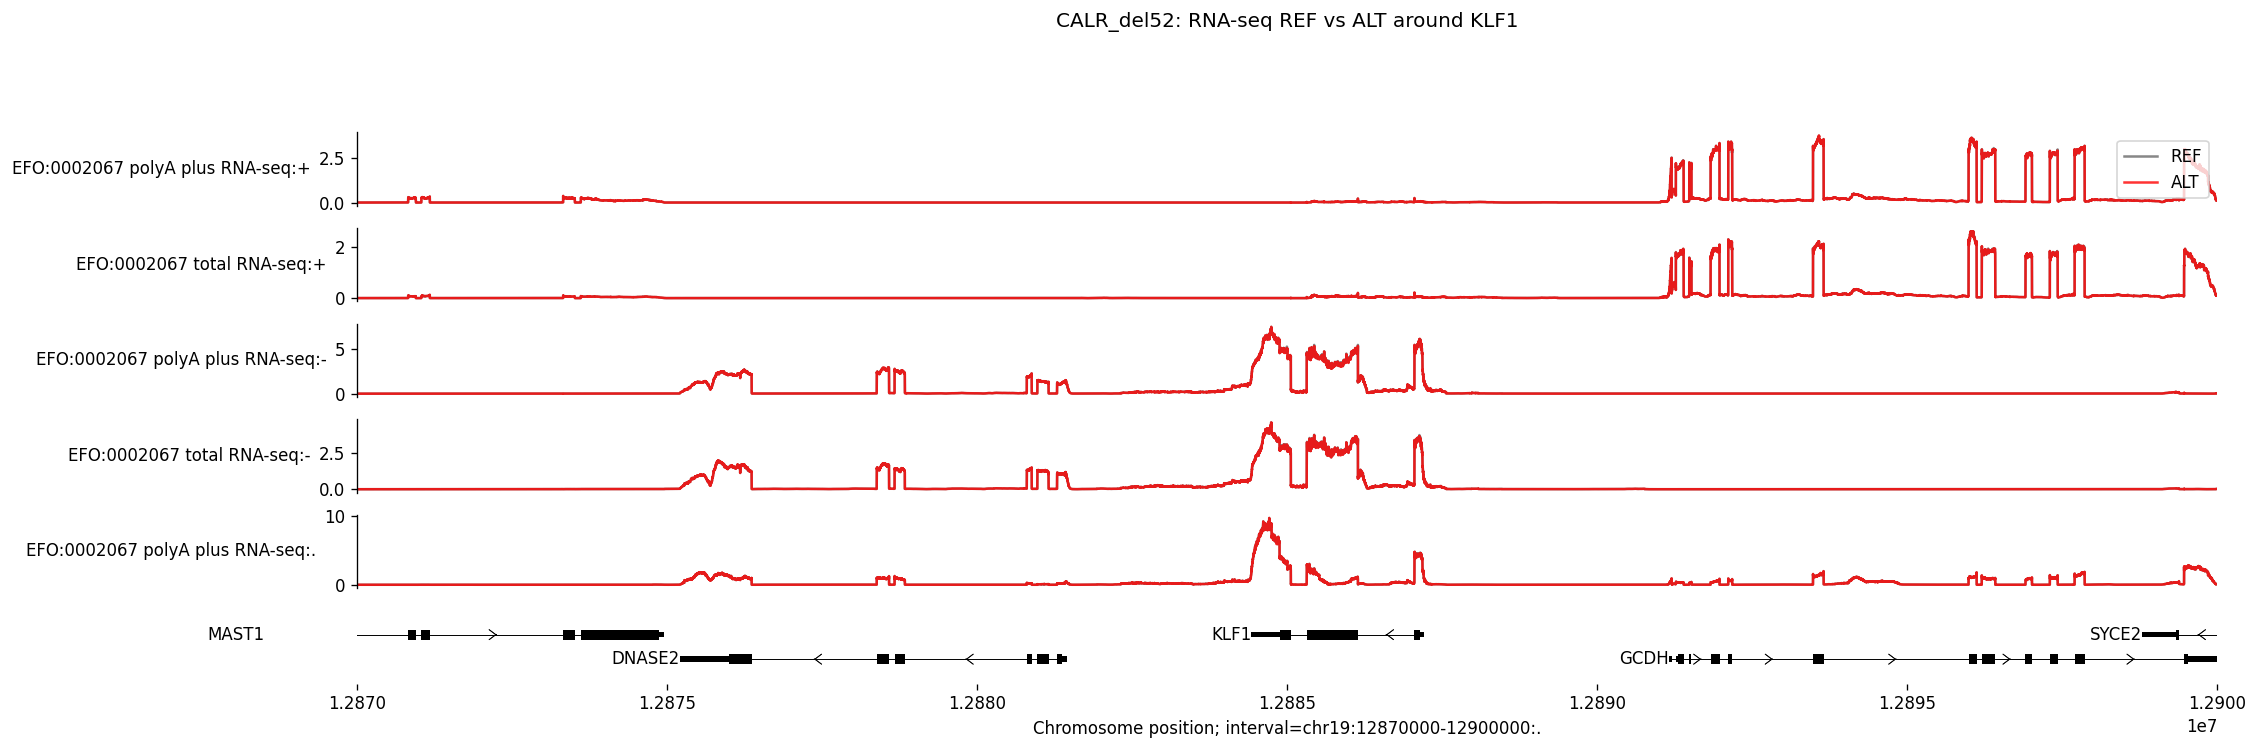

In [10]:
show_rna(genome.Interval(CHROM, 12_870_000, 12_900_000),
         f"{VARIANT_NAME}: RNA-seq REF vs ALT around {KLF1_GENE}")

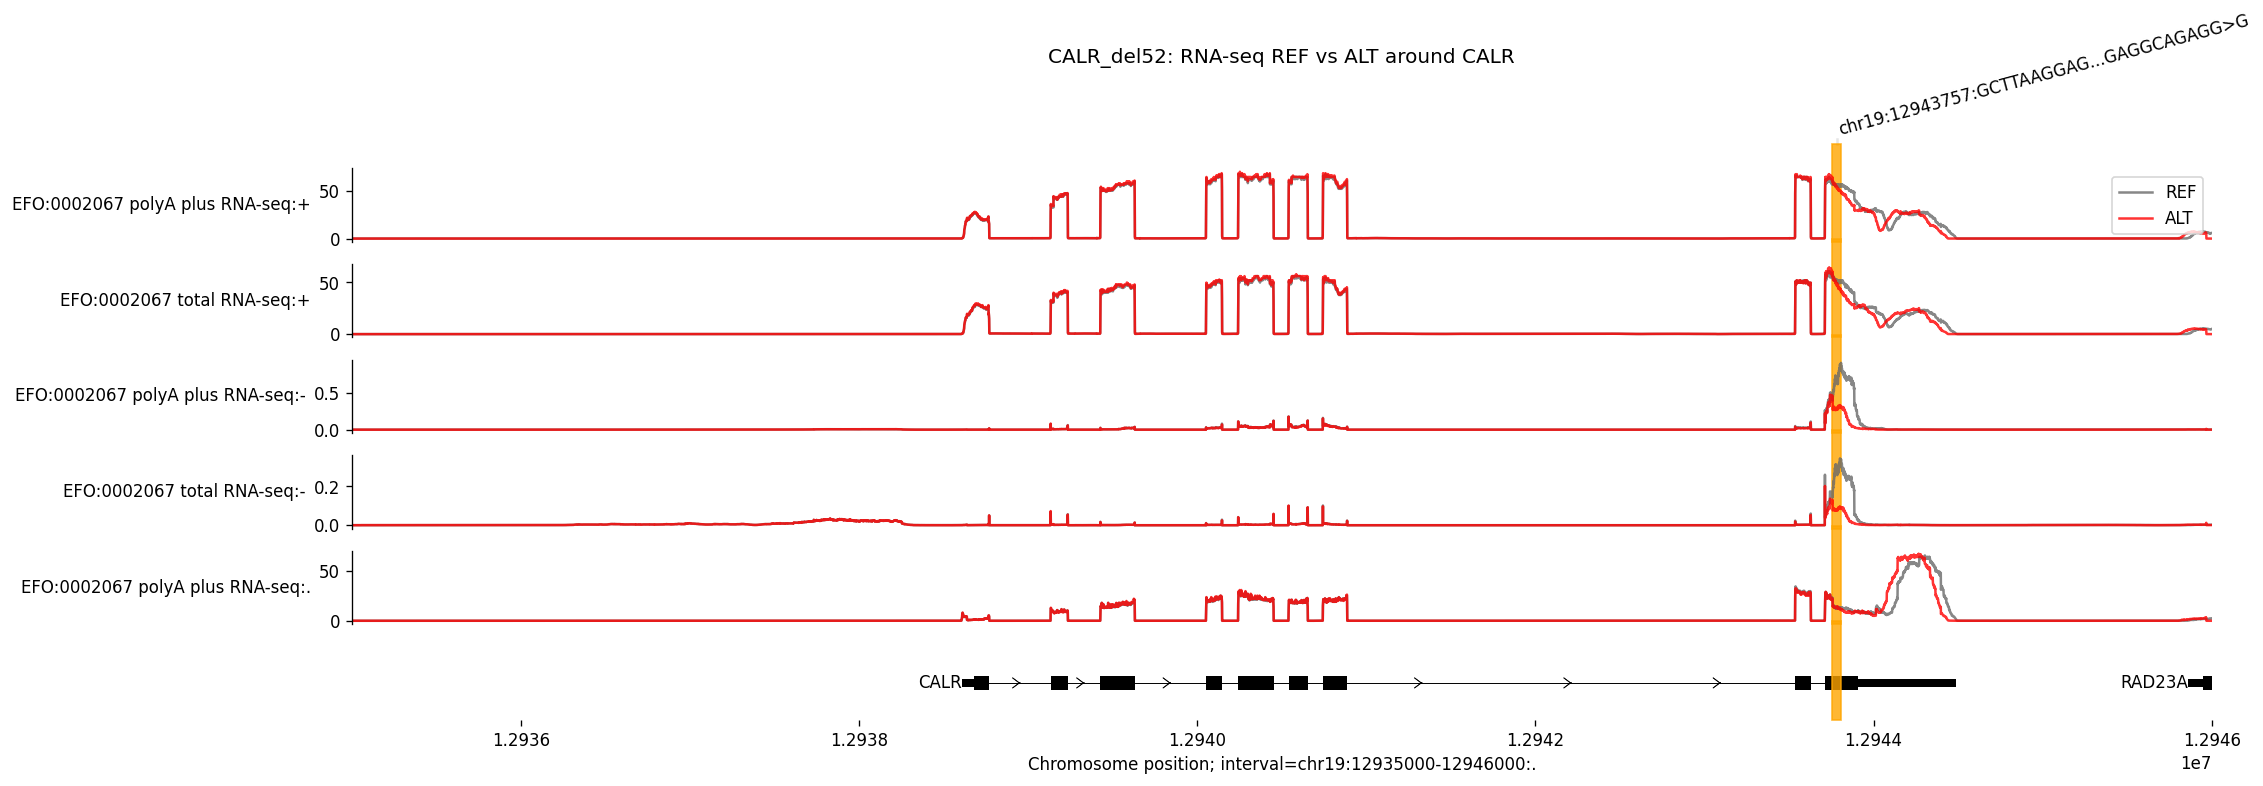

In [20]:
show_rna(genome.Interval(CHROM, 12_935_000, 12_946_000),
         f"{VARIANT_NAME}: RNA-seq REF vs ALT around CALR")

In [12]:
# Contact maps came back for ALL cell types (~28). ContactMapsDiff caps at 10, and
# 28 heatmaps is unreadable anyway -> select your cell type(s) by curie first.
cm_ref = by_ontology(outputs.reference.contact_maps, ONTOLOGY_TERMS)
cm_alt = by_ontology(outputs.alternate.contact_maps, ONTOLOGY_TERMS)

if cm_ref is None or cm_ref.num_tracks == 0:
    avail = list(dict.fromkeys(o.ontology_curie
                               for o in outputs.reference.contact_maps.ontology_terms))
    print("No contact map for", ONTOLOGY_TERMS, "- available curies:", avail)
    print("Set ONTOLOGY_TERMS to one of these (K562 is EFO:0002067) and re-run.")
else:
    print("contact-map tracks:", cm_ref.num_tracks,
          "| curies:", [o.ontology_curie for o in cm_ref.ontology_terms])
    plot_components.plot(
        [plot_components.ContactMapsDiff(tdata=cm_alt - cm_ref)],
        interval=interval,
        title=f"{VARIANT_NAME}: contact-map difference ALT - REF",
    )
    plt.show()

No contact map for ['EFO:0002067'] - available curies: ['EFO:0003042', 'EFO:0009318', 'EFO:0002824', 'EFO:0001196', 'EFO:0002784', 'EFO:0007073', 'EFO:0003045', 'EFO:0005903', 'EFO:0002791', 'CL:0002620', 'EFO:0001187', 'EFO:0009747']
Set ONTOLOGY_TERMS to one of these (K562 is EFO:0002067) and re-run.


## Score: quantitative effects

`GeneMaskLFCScorer` → gene-resolved log-fold change per gene. `ContactMapScorer` → local contact
disruption (mean |ALT−REF| over the variant bin's contacts, 1 Mb).

Below: a **per-gene LFC table** across the neighbours (the quantitative version of the RNA-seq
divergence you see in the CALR plot), then KLF1 alone, then the contact score. Use
**`quantile_score`** (rank vs a common-variant background) to judge whether an effect is *large*,
not the raw LFC alone.

In [13]:
scorers = [
    variant_scorers.GeneMaskLFCScorer(requested_output=dna_client.OutputType.RNA_SEQ),
    variant_scorers.ContactMapScorer(),
]
scores = model.score_variant(interval=interval, variant=variant, variant_scorers=scorers)
df = variant_scorers.tidy_scores(scores)
df.head()

,variant_id,scored_interval,gene_id,gene_name,gene_type,gene_strand,junction_Start,junction_End,output_type,variant_scorer,...,ontology_curie,biosample_name,biosample_type,biosample_life_stage,gtex_tissue,data_source,endedness,genetically_modified,raw_score,quantile_score
0,chr19:12943757:GCTTAAGGAGGAGGAAGAAGACAAGAAACGC...,chr19:12419470-13468046:.,ENSG00000008441,NFIX,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000047,neuronal stem cell,in_vitro_differentiated_cells,embryonic,,encode,paired,False,-0.080145,-0.999904
1,chr19:12943757:GCTTAAGGAGGAGGAAGAAGACAAGAAACGC...,chr19:12419470-13468046:.,ENSG00000008441,NFIX,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000062,osteoblast,primary_cell,adult,,encode,paired,False,-0.019729,-0.999433
2,chr19:12943757:GCTTAAGGAGGAGGAAGAAGACAAGAAACGC...,chr19:12419470-13468046:.,ENSG00000008441,NFIX,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000084,T-cell,primary_cell,adult,,encode,paired,False,0.037608,0.999617
3,chr19:12943757:GCTTAAGGAGGAGGAAGAAGACAAGAAACGC...,chr19:12419470-13468046:.,ENSG00000008441,NFIX,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000084,T-cell,primary_cell,adult,,encode,single,False,0.012203,0.997461
4,chr19:12943757:GCTTAAGGAGGAGGAAGAAGACAAGAAACGC...,chr19:12419470-13468046:.,ENSG00000008441,NFIX,protein_coding,+,None,None,RNA_SEQ,GeneMaskLFCScorer(requested_output=RNA_SEQ),...,CL:0000115,endothelial cell,in_vitro_differentiated_cells,adult,,encode,single,False,-0.047404,-0.999780


In [14]:
# Per-gene LFC across the neighbours, filtered to your ontology (K562).
# This is the quantitative version of the RNA-seq plots: turns "the colours diverged"
# into "gene X predicted LFC = Y". The variant sits in CALR, so CALR is the in-scope row;
# KLF1 should be ~0; FARSA/SYCE2/RAD23A help spot any spurious neighbour effects.
GENES = ["KLF1", "CALR", "FARSA", "SYCE2", "GCDH", "RAD23A", "DNASE2"]
lfc = df[(df.get("output_type") == "RNA_SEQ")]
if "ontology_curie" in lfc.columns:
    lfc = lfc[lfc["ontology_curie"].isin(set(ONTOLOGY_TERMS))]
tbl = (lfc[lfc["gene_name"].isin(GENES)]
       [[c for c in ["gene_name","gene_strand","ontology_curie","raw_score","quantile_score"]
         if c in lfc.columns]]
       .sort_values("gene_name"))
print("=== Per-gene RNA-seq LFC (", ", ".join(ONTOLOGY_TERMS), ") ===")
print(tbl.to_string(index=False) if len(tbl) else "(no rows — check gene names / ontology)")

# KLF1 alone (the cis null check)
klf1 = df[df["gene_name"] == KLF1_GENE]
print("\n=== KLF1 only ===")
print(klf1[[c for c in ["gene_name","output_type","ontology_curie","raw_score","quantile_score"]
            if c in klf1.columns]].to_string(index=False))

# Contact-map disruption score
cm = df[df["output_type"] == "CONTACT_MAPS"] if "output_type" in df.columns else df
print("\n=== Local contact-map disruption (ALT vs REF) ===")
print(cm[[c for c in ["ontology_curie","raw_score","quantile_score"] if c in cm.columns]]
      .to_string(index=False))

df.to_csv("ag_scores_calr_klf1.tsv", sep="\t", index=False)
print("\nwrote ag_scores_calr_klf1.tsv")

=== Per-gene RNA-seq LFC ( EFO:0002067 ) ===
gene_name gene_strand ontology_curie  raw_score  quantile_score
     CALR           +    EFO:0002067   0.007935        0.982497
     CALR           +    EFO:0002067  -0.017153       -0.998728
     CALR           +    EFO:0002067  -0.017196       -0.998471
   DNASE2           -    EFO:0002067   0.000025        0.092027
   DNASE2           -    EFO:0002067   0.000184        0.259272
   DNASE2           -    EFO:0002067   0.001774        0.686934
    FARSA           -    EFO:0002067  -0.001313       -0.648619
    FARSA           -    EFO:0002067  -0.001112       -0.628119
    FARSA           -    EFO:0002067  -0.000698       -0.431257
     GCDH           +    EFO:0002067  -0.000875       -0.568981
     GCDH           +    EFO:0002067  -0.001330       -0.716204
     GCDH           +    EFO:0002067   0.001502        0.641886
     KLF1           -    EFO:0002067  -0.005517       -0.963724
     KLF1           -    EFO:0002067  -0.004386       -0.94

## (optional) Run the other lesion, or compare both

The Config cell builds both `del52` and `ins5`. To run the other one, set `variant = ins5` in
the Config build cell and re-run predict + score. To compare them quantitatively in one table,
score a list:

```python
both = model.score_variant(interval=interval, variant=del52, variant_scorers=scorers)
# ...repeat for ins5, then concat the tidy_scores frames and compare KLF1 + CALR rows.
```

Remember (see the top cell): for these coding frameshifts the **KLF1** numbers are a cis null
check; the **CALR-self** rows (its own RNA-seq/splicing/contacts) are the in-scope cis readout.

## Experiment: delete the CRISPRi-validated regulatory element

Unlike the coding indels, this is a *cis* perturbation AlphaGenome can actually model: remove the
validated element and ask whether its target genes' predicted expression moves — an in-silico
analogue of the CRISPRi-FlowFISH experiment.

**Read these caveats first, they shape the interpretation:**
- **Which element.** `GH19J013089` / **LOC117125597** is the CRISPRi-FlowFISH-validated CALR +
  DNASE2 + KLF1 element, at hg38 **~chr19:13,089 kb** (3′ of CALR). This is *different* from the
  KLF1-proximal `GH19J012880` (~12,880 kb). Set the coordinates for whichever you intend.
- **Direction.** It was validated as a **negatively-acting** CRE (silencer) for those genes — so
  removing it is expected to *raise* CALR/DNASE2/KLF1, not lower them. Mind the sign.
- **CRISPRi ≠ deletion.** dCas9-KRAB represses chromatin without changing sequence; AlphaGenome
  can't model that, so a whole-element **deletion** is our sequence proxy. A point SNV inside the
  element would likely be too small to register.
- **Big indel = big caveat.** A multi-kb deletion is far larger than the del52; indel/registration
  reliability concerns are *greater* here. A null may mean "model didn't learn this long-range
  dependency," not "no biology." Treat a positive coordinated trio shift as the informative result.

In [15]:
# --- CRISPRi-validated element coordinates (hg38) — VERIFY in UCSC GeneHancer track ---
# Replace with the exact element span from the GeneHancer/UCSC record before trusting output.
ENH_START = 13_089_000     # placeholder — set to GH19J013089 / LOC117125597 start
ENH_END   = 13_091_000     # placeholder — set to its end
ENH_NAME  = "LOC117125597_del"

# Build a whole-element deletion: REF = anchor + element; ALT = anchor base.
enh_anchor = ENH_START - 1
enh_ref = fetch(CHROM, enh_anchor, ENH_END)          # Ensembl/FASTA, same fetch() as indels
enh_alt = enh_ref[0]
enh_del = genome.Variant(CHROM, enh_anchor, enh_ref, enh_alt, ENH_NAME)
print(f"{ENH_NAME}: POS {enh_anchor} | REF {len(enh_ref)} bp | ALT {len(enh_alt)} bp "
      f"| deletes {len(enh_ref)-1} bp")

# 1 Mb window centered on the element so all validated targets are in view.
enh_center   = (ENH_START + ENH_END) // 2
enh_start    = enh_center - SEQ_LEN // 2
enh_interval = genome.Interval(CHROM, enh_start, enh_start + SEQ_LEN)
for tss, name in [(12_887_201, "KLF1"), (12_938_609, "CALR"), (ENH_START, "element")]:
    print(f"  window contains {name}:", enh_interval.start <= tss <= enh_interval.end)

LOC117125597_del: POS 13088999 | REF 2002 bp | ALT 1 bp | deletes 2001 bp
  window contains KLF1: True
  window contains CALR: True
  window contains element: True


In [16]:
# Score the element deletion against the validated + candidate targets.
enh_scores = model.score_variant(
    interval=enh_interval, variant=enh_del,
    variant_scorers=[variant_scorers.GeneMaskLFCScorer(
        requested_output=dna_client.OutputType.RNA_SEQ)])
enh_df = variant_scorers.tidy_scores(enh_scores)

VALIDATED = ["CALR", "DNASE2", "KLF1"]              # CRISPRi-FlowFISH trio
CANDIDATES = ["LYL1", "NFIX", "RNASEH2A", "GCDH", "TRMT1", "RAD23A"]  # wider GeneHancer set
rows = enh_df[(enh_df.get("output_type") == "RNA_SEQ")]
if "ontology_curie" in rows.columns:
    rows = rows[rows["ontology_curie"].isin(set(ONTOLOGY_TERMS))]

print("=== Validated targets (expect coordinated change; sign = UP if silencer removed) ===")
print(rows[rows["gene_name"].isin(VALIDATED)]
      [[c for c in ["gene_name","gene_strand","raw_score","quantile_score"] if c in rows.columns]]
      .sort_values("gene_name").to_string(index=False))
print("\n=== Wider candidate targets ===")
print(rows[rows["gene_name"].isin(CANDIDATES)]
      [[c for c in ["gene_name","gene_strand","raw_score","quantile_score"] if c in rows.columns]]
      .sort_values("gene_name").to_string(index=False))

enh_df.to_csv("ag_enhancer_deletion_scores.tsv", sep="\t", index=False)
print("\nwrote ag_enhancer_deletion_scores.tsv")

=== Validated targets (expect coordinated change; sign = UP if silencer removed) ===
gene_name gene_strand  raw_score  quantile_score
     CALR           +   0.000312        0.363304
     CALR           +   0.000604        0.528697
     CALR           +  -0.002118       -0.737944
   DNASE2           -  -0.000829       -0.520335
   DNASE2           -  -0.000938       -0.576732
   DNASE2           -   0.001638        0.661785
     KLF1           -  -0.005672       -0.966109
     KLF1           -  -0.005845       -0.974781
     KLF1           -  -0.011943       -0.994933

=== Wider candidate targets ===
gene_name gene_strand  raw_score  quantile_score
     GCDH           +   0.000189        0.291254
     GCDH           +   0.000369        0.431257
     GCDH           +  -0.000638       -0.412290
     LYL1           -   0.061937        0.999775
     LYL1           -   0.050185        0.999741
     LYL1           -   0.103259        0.999899
     NFIX           +  -0.043338       -0.999599


### Reading the element-deletion result

- **Coordinated movement of CALR + DNASE2 + KLF1** (same direction, non-trivial magnitude, high
  `quantile_score`) = AlphaGenome reproduces the validated dependency in silico. Given it's a
  *silencer*, the expected direction is **up**.
- **The trio moving together** is the key signature — it distinguishes a true shared-element effect
  from incidental single-gene noise, and is exactly the coordination your scRNA-seq test looks for.
- **A flat/near-null result** is ambiguous: AlphaGenome may simply not capture this long-range
  (~150–200 kb to KLF1) silencer dependency. Don't read it as "the element doesn't work" — the
  CRISPRi data already established that it does.
- **Control:** repeat with a size-matched deletion in a gene desert; if it perturbs neighbours
  similarly, the element 'effect' is partly registration artefact.

## Interpretation & caveats — read before trusting any number

- **Mechanism (the crux):** the canonical exon-9 indels are **coding** and act in **trans** via
  mutant CALR–MPL–JAK/STAT signaling. A sequence-to-assay model only sees **cis**. So a near-zero
  KLF1 effect is **expected and not informative about the real mechanism**; the in-scope cis
  question is each lesion's effect on **CALR itself**. A non-trivial KLF1 cis effect would be the
  surprise — cross-check it against the PCHi-C / rE2G / scE2G layers.
- **Indel reliability:** AlphaGenome accepts indels, but its variant-effect benchmarks are
  SNV-centric and indel behaviour is **less validated**, especially for a 52 bp event. Sanity-check
  on a *known* indel before trusting the del52 call.
- **ins5 coordinate is derived** (from c.1142A>C = g.12943801); confirm `g.12943813_12943814insTTGTC`
  via Ensembl VEP or Mutalyzer before relying on it.
- **Contact resolution** is ~2 kb bins; KLF1 and CALR are ~56 kb apart — perturbation of the local
  contact neighbourhood, not a specific loop.
- **Online API = inference only.** No fine-tuning here. If a real cis effect survives the
  experimental cross-check, *that* is the trigger for Borzoi PEFT on your own expression data.
- **Reproducible write-up:** `quarto convert` this notebook to a `.qmd` and render to HTML/PDF —
  same kernel, same code.